# 01 · Exploring the Telugu speech data

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pavanadityav-ai/telugu-asr-whisper/blob/main/notebooks/01_data_exploration.ipynb)

**Goal:** understand the data before training anything: how much audio there is, who is speaking, what the text looks like, and how Whisper's tokenizer handles Telugu.

**Runtime:** no GPU needed. *Runtime → Run all*. Takes about 5 minutes (mostly downloading 2.3 GB of audio).

In [ ]:
# Setup: install libraries, get the project code, connect Google Drive
!pip install -q -U datasets jiwer
import os, sys
if not os.path.isdir("telugu-asr-whisper"):
    !git clone -q https://github.com/pavanadityav-ai/telugu-asr-whisper
sys.path.insert(0, "telugu-asr-whisper")

from google.colab import drive
drive.mount("/content/drive")
OUT = "/content/drive/MyDrive/telugu-asr-whisper"  # results are saved here
os.makedirs(OUT, exist_ok=True)
print("Saving results to:", OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saving results to: /content/drive/MyDrive/telugu-asr-whisper


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.audio_utils import load_fleurs_telugu, decode_audio

te = load_fleurs_telugu()
print(te)

README.md:   0%|          | 0.00/386k [00:00<?, ?B/s]

parquet-data/te_in/train-00000-of-00001.(…): reconstructing file:   0%|          |  0.00B / 1.81GB            

parquet-data/te_in/train-00000-of-00001.(…): downloading bytes:           |  0.00B            

parquet-data/te_in/validation-00000-of-0(…): reconstructing file:   0%|          |  0.00B /  205MB            

parquet-data/te_in/validation-00000-of-0(…): downloading bytes:           |  0.00B            

parquet-data/te_in/test-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B /  332MB            

parquet-data/te_in/test-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2302 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/311 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/472 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'num_samples', 'path', 'audio', 'transcription', 'raw_transcription', 'gender', 'lang_id', 'language', 'lang_group_id'],
        num_rows: 2302
    })
    validation: Dataset({
        features: ['id', 'num_samples', 'path', 'audio', 'transcription', 'raw_transcription', 'gender', 'lang_id', 'language', 'lang_group_id'],
        num_rows: 311
    })
    test: Dataset({
        features: ['id', 'num_samples', 'path', 'audio', 'transcription', 'raw_transcription', 'gender', 'lang_id', 'language', 'lang_group_id'],
        num_rows: 472
    })
})


## 1. How much audio do we have?
`num_samples` is the length of a clip in samples. The audio has 16,000 samples per second, so `seconds = num_samples / 16,000`. Whisper reads at most 30 seconds at a time, so we also count clips longer than that.

In [ ]:
rows = []
for split in ["train", "validation", "test"]:
    secs = np.array(list(te[split]["num_samples"])) / 16_000
    rows.append({"split": split, "clips": len(secs), "hours": secs.sum() / 3600,
                 "mean_sec": secs.mean(), "min_sec": secs.min(), "max_sec": secs.max(),
                 "over_30_sec": int((secs > 30).sum())})
summary = pd.DataFrame(rows).round(2)
summary

,split,clips,hours,mean_sec,min_sec,max_sec,over_30_sec
0,train,2302,7.92,12.38,1.44,41.22,4
1,validation,311,0.89,10.35,3.60,32.22,1
2,test,472,1.45,11.05,4.20,30.48,1


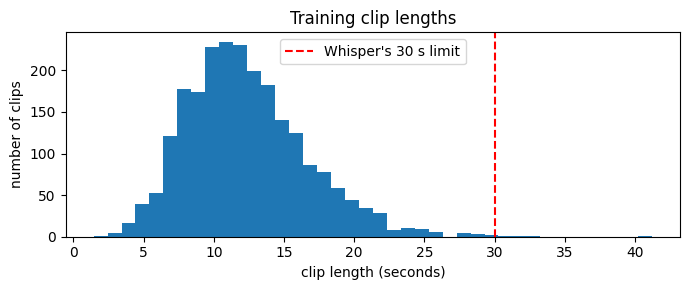

In [ ]:
train_secs = np.array(list(te["train"]["num_samples"])) / 16_000
plt.figure(figsize=(7, 3))
plt.hist(train_secs, bins=40)
plt.axvline(30, color="red", linestyle="--", label="Whisper's 30 s limit")
plt.xlabel("clip length (seconds)"); plt.ylabel("number of clips")
plt.title("Training clip lengths"); plt.legend(); plt.tight_layout()
plt.savefig(f"{OUT}/clip_lengths.png", dpi=150)
plt.show()

## 2. Who is speaking?

In [ ]:
gender = te["train"].features["gender"]
names = getattr(gender, "names", None)
values, counts = np.unique(list(te["train"]["gender"]), return_counts=True)
for v, c in zip(values, counts):
    print(f"{names[v] if names else v}: {c} clips ({100 * c / counts.sum():.0f}%)")

male: 643 clips (28%)
female: 1659 clips (72%)


## 3. Listen to a clip

In [ ]:
from IPython.display import Audio, display

example = te["train"][0]
print(example["transcription"])
display(Audio(decode_audio(example["audio"]), rate=16_000))

డెంగ్ జియావోపింగ్ నాయకత్వంలో మొదటి ఆర్థిక సంస్కరణలు జరిగాయి


## 4. What does the text look like?
Telugu glues many endings onto a word (నాయకత్వం → నాయకత్వంలో, "in the leadership"). So the same word appears in many forms, and many test words never appear in training. That is one reason we report **CER** (character error rate) next to WER.

In [ ]:
from src.text_utils import normalize_text, script_profile

train_text = [normalize_text(t) for t in te["train"]["transcription"]]
test_text = [normalize_text(t) for t in te["test"]["transcription"]]

words = np.array([len(t.split()) for t in train_text])
chars = np.array([len(t) for t in train_text])
print(f"Average sentence: {words.mean():.1f} words, {chars.mean():.0f} characters")

train_vocab = {w for t in train_text for w in t.split()}
test_words = [w for t in test_text for w in t.split()]
unseen = [w for w in test_words if w not in train_vocab]
print(f"Different words in training: {len(train_vocab):,}")
print(f"Test words never seen in training: {100 * len(unseen) / len(test_words):.0f}%")
print("Examples:", unseen[:10])

latin = sum(script_profile(t)["latin"] > 0 for t in train_text)
print(f"Training sentences containing English letters: {latin}")

# Save the training vocabulary for the error analysis notebook
with open(f"{OUT}/train_vocab.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(sorted(train_vocab)))

Average sentence: 15.7 words, 118 characters
Different words in training: 9,474
Test words never seen in training: 33%
Examples: ['లగ్జరీ', 'రిసార్ట్', 'స్', 'క్రియలు', 'ఆబ్జెక్టుల', 'తేడాను', 'గుర్తించడానికి', 'స్వంతం', 'ఆలోచనలతో', 'తీసుకోవాలని']
Training sentences containing English letters: 258


## 5. How does Whisper's tokenizer see Telugu?
Whisper turns text into **tokens** before learning it. Its tokenizer was built mostly from English, so Telugu needs many more tokens for the same meaning. Whisper also cannot write more than **448 tokens** for one clip.

In [ ]:
from transformers import WhisperTokenizer

tok = WhisperTokenizer.from_pretrained("openai/whisper-small")
english = "The first economic reforms happened under the leadership of Deng Xiaoping"
telugu = normalize_text(te["train"][0]["transcription"])
for name, s in [("English", english), ("Telugu", telugu)]:
    n = len(tok(s, add_special_tokens=False).input_ids)
    print(f"{name:8s} {len(s):3d} characters -> {n:3d} tokens  ({n / len(s):.2f} tokens per character)")

lens = np.array([len(tok(t).input_ids) for t in train_text])
print(f"\nTokens per Telugu training sentence: average {lens.mean():.0f}, longest {lens.max()}")
print("Sentences over the 448-token limit:", int((lens > 448).sum()))

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/836k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/494k [00:00<?, ?B/s]

normalizer.json:   0%|          | 0.00/52.7k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

English   73 characters ->  13 tokens  (0.18 tokens per character)
Telugu    59 characters -> 112 tokens  (1.90 tokens per character)

Tokens per Telugu training sentence: average 221, longest 519
Sentences over the 448-token limit: 21


## 6. Save a summary

In [ ]:
import json
data_summary = {
    "splits": summary.to_dict(orient="records"),
    "train_vocab_size": len(train_vocab),
    "test_unseen_word_rate": len(unseen) / len(test_words),
    "avg_tokens_per_sentence": float(lens.mean()),
}
with open(f"{OUT}/data_summary.json", "w") as f:
    json.dump(data_summary, f, indent=2)
data_summary

{'splits': [{'split': 'train',
   'clips': 2302,
   'hours': 7.92,
   'mean_sec': 12.38,
   'min_sec': 1.44,
   'max_sec': 41.22,
   'over_30_sec': 4},
  {'split': 'validation',
   'clips': 311,
   'hours': 0.89,
   'mean_sec': 10.35,
   'min_sec': 3.6,
   'max_sec': 32.22,
   'over_30_sec': 1},
  {'split': 'test',
   'clips': 472,
   'hours': 1.45,
   'mean_sec': 11.05,
   'min_sec': 4.2,
   'max_sec': 30.48,
   'over_30_sec': 1}],
 'train_vocab_size': 9474,
 'test_unseen_word_rate': 0.33126425133012416,
 'avg_tokens_per_sentence': 220.57341442224154}

## My notes


1. We have only 7.9 hours of training audio, and 21 sentences are longer than Whisper's 448-token limit, so they are removed.
2. The same sentence needs 13 tokens in English but 112 tokens in Telugu, about 9 times more, because Whisper's tokenizer splits Telugu into very small pieces.
3. 33% of the words in the test set never appear in the training data, because Telugu adds many endings to words.
4. 72% of the training clips are female voices, so the model may make more mistakes on male voices.